# Test thật: EdNet gốc và cùng dữ liệu đổi nhãn OWN

Hai mô hình DAS3H d=0 huấn luyện trên log đúng/sai thật KT4. Cùng các lượt làm, đáp án, timestamp và splits. Không dùng dữ liệu Santa như lịch sử người học. Lịch sử cohort không bị cắt ở 200 attempts; đây vẫn là mẫu người học, không phải toàn KT4. Kết quả pilot ở notebook 02 được giữ riêng.

In [1]:
from pathlib import Path
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
ROOT=Path.cwd().resolve()
if not (ROOT/'config/policy.json').exists(): ROOT=ROOT.parent
OUT=ROOT/'outputs/das3h_comparison'
p=json.loads((OUT/'protocol.json').read_text(encoding='utf-8'))
assert p['status']=='completed'
m=pd.read_csv(OUT/'metrics.csv')
a=pd.read_csv(OUT/'aggregate_metrics.csv')
ci=pd.read_csv(OUT/'paired_bootstrap.csv')
verification=json.loads((OUT/'verification.json').read_text(encoding='utf-8'))
assert verification['passed']
print('Real learners:',p['sample']['learners'])
print('Real completed attempts:',p['sample']['attempts'])
print('Unique observed questions:',p['observed_questions'])
print('All history:',p['max_events_per_learner'] is None)
print('Mapping SHA256:',p['own_projection_sha256'])
print('Verification:',verification)
print('Rows by Part:',p['observed_parts'])

Real learners: 3000
Real completed attempts: 413744
Unique observed questions: 11544
All history: True
Mapping SHA256: d19ecbf41c79ee18818ecdd50764cf0a2f3bf7bdaa3eb632c6c3eac95b50fdb7
Verification: {'passed': True, 'raw_zip_learners_reconstructed': 10, 'all_row_counts_recomputed': True, 'test_labels_match_real_attempt_cache': True, 'metrics_recomputed_from_predictions': True, 'validation_selection_verified': True, 'hashes_verified': True, 'checks': [{'seed': 42, 'test_rows_verified': 65847, 'test_learners': 450, 'identical_rows_and_labels': True}, {'seed': 43, 'test_rows_verified': 65256, 'test_learners': 450, 'identical_rows_and_labels': True}, {'seed': 44, 'test_rows_verified': 51066, 'test_learners': 450, 'identical_rows_and_labels': True}], 'private_interactions_not_exported': True, 'attempts_per_learner': {'min': 10, 'median': 24.0, 'mean': 137.91466666666668, 'max': 9404}}
Rows by Part: {'p5': 211087, 'p2': 76703, 'p6': 34276, 'p1': 32077, 'p3': 23552, 'p4': 20972, 'p7': 15077}


## Protocol

70/15/15 learner-disjoint, ba split seed trên cùng cohort. Cumulative wins/attempts trong 1h/1d/7d/30d/vô hạn, log1p, chỉ timestamp trước đó. Cùng submit không nhìn đáp án của nhau. C chọn theo validation log loss; test không chọn nhãn/ngưỡng/C. Không phải chronological split toàn cục hoặc question-disjoint test.

In [2]:
display(m[['seed','variant','scope','auc','log_loss','brier','accuracy','train_attempts','validation_attempts','test_attempts','catalog_skills','train_observed_skills','C','converged']])
display(pd.read_csv(OUT/'validation_selection.csv'))

,seed,variant,scope,auc,log_loss,brier,accuracy,train_attempts,validation_attempts,test_attempts,catalog_skills,train_observed_skills,C,converged
0,42,ednet_original_188,all_test,0.705001,0.578811,0.197292,0.698392,281250,66647,65847,188,187,1.0,True
1,42,ednet_original_188,mapped_test,0.704200,0.578022,0.197009,0.698619,281250,66647,61477,188,187,1.0,True
2,42,ednet_original_188,unmapped_test,0.714038,0.589910,0.201272,0.695195,281250,66647,4370,188,187,1.0,True
3,42,ednet_original_188,p1,0.719544,0.493280,0.159750,0.776984,281250,66647,5596,188,187,1.0,True
4,42,ednet_original_188,p2,0.683648,0.560026,0.189081,0.720833,281250,66647,12677,188,187,1.0,True
5,42,ednet_original_188,p3,0.732509,0.504616,0.166447,0.755585,281250,66647,4476,188,187,1.0,True
6,42,ednet_original_188,p4,0.724418,0.521479,0.172045,0.753163,281250,66647,4821,188,187,1.0,True
7,42,ednet_original_188,p5,0.678368,0.625579,0.217587,0.654257,281250,66647,31211,188,187,1.0,True
8,42,ednet_original_188,p6,0.725332,0.560699,0.189475,0.716266,281250,66647,5195,188,187,1.0,True
9,42,ednet_original_188,p7,0.701415,0.557271,0.187209,0.719936,281250,66647,1871,188,187,1.0,True


,seed,variant,C,validation_log_loss,converged
0,42,ednet_original_188,0.1,0.581145,True
1,42,ednet_original_188,1.0,0.580327,True
2,42,ednet_original_188,10.0,0.596188,True
3,42,ednet_relabeled_own_92,0.1,0.586358,True
4,42,ednet_relabeled_own_92,1.0,0.584557,True
5,42,ednet_relabeled_own_92,10.0,0.599236,True
6,43,ednet_original_188,0.1,0.585368,True
7,43,ednet_original_188,1.0,0.580753,True
8,43,ednet_original_188,10.0,0.595387,True
9,43,ednet_relabeled_own_92,0.1,0.590111,True


## Đối chứng trực tiếp trên toàn bộ cùng lượt test

188 tag EdNet so với 92 tag nội dung OWN. Không lọc bỏ câu chưa có OWN; câu đó vẫn giữ item bias nhưng không có skill history. Các numeric tag gốc bao gồm những thuộc tính được tách riêng ở OWN, nên đây không phải tác động riêng của clustering.

,scope,auc_mean,auc_std,log_loss_mean,log_loss_std,brier_mean,brier_std,accuracy_mean,accuracy_std
variant,,,,,,,,,
ednet_original_188,all_test,0.699760,0.004621,0.590793,0.010650,0.202279,0.004478,0.688588,0.008887
ednet_relabeled_own_92,all_test,0.695972,0.006697,0.593015,0.011914,0.203444,0.005016,0.684654,0.009832


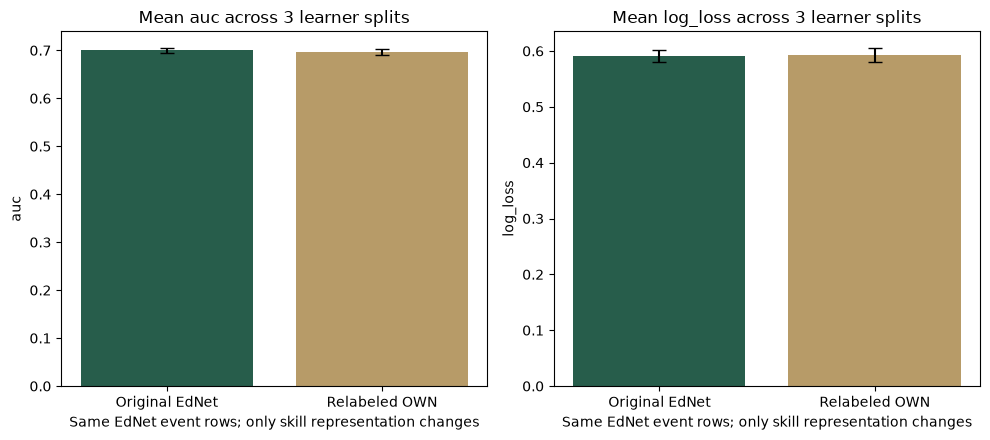

In [3]:
top=a[a.scope=='all_test'].set_index('variant').loc[['ednet_original_188','ednet_relabeled_own_92']]
display(top)
fig,axes=plt.subplots(1,2,figsize=(10,4.5))
for ax,metric in zip(axes,['auc','log_loss']):
    ax.bar(['Original EdNet','Relabeled OWN'],top[metric+'_mean'],yerr=top[metric+'_std'].fillna(0),capsize=5,color=['#275d4b','#b79b68'])
    ax.set(xlabel='Same EdNet event rows; only skill representation changes',ylabel=metric,title='Mean '+metric+' across 3 learner splits')
fig.tight_layout();plt.show()
fig.savefig(OUT/'original_vs_relabeled.png',dpi=150,bbox_inches='tight')

## Bất định: paired bootstrap theo người học

Chênh AUC = OWN − gốc. CI riêng từng seed, không phải 3 fold độc lập. CI bao gồm 0 không chứng minh tương đương. Không đặt equivalence margin sau khi xem test.

,scope,delta_auc_own_minus_original,ci95_low,ci95_high,bootstrap_repeats,unit,seed
0,all_test,-0.001299,-0.003954,0.000352,200,paired student cluster,42
1,mapped_test,-0.000936,-0.003060,0.000484,200,paired student cluster,42
2,unmapped_test,-0.005884,-0.018423,0.003157,200,paired student cluster,42
3,all_test,-0.004382,-0.005816,-0.003043,200,paired student cluster,43
4,mapped_test,-0.003288,-0.004643,-0.001862,200,paired student cluster,43
5,unmapped_test,-0.019283,-0.027461,-0.013456,200,paired student cluster,43
6,all_test,-0.005682,-0.007753,-0.003804,200,paired student cluster,44
7,mapped_test,-0.004753,-0.006445,-0.003005,200,paired student cluster,44
8,unmapped_test,-0.018738,-0.028810,-0.009666,200,paired student cluster,44


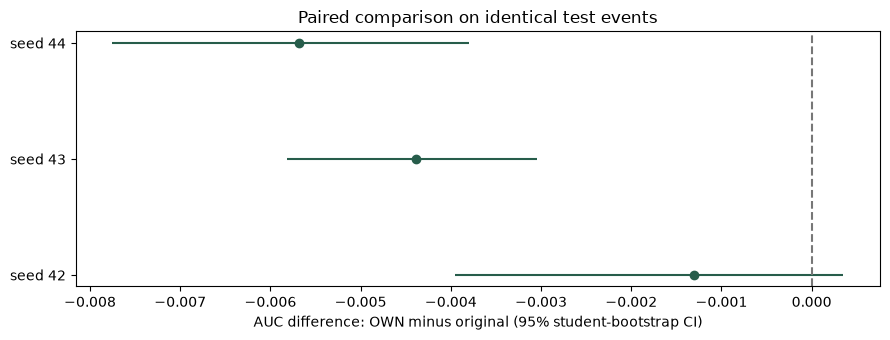

In [4]:
display(ci)
sel=ci[ci.scope=='all_test'].reset_index(drop=True)
fig,ax=plt.subplots(figsize=(9,3.5))
y=np.arange(len(sel));ax.hlines(y,sel.ci95_low,sel.ci95_high,color='#275d4b');ax.scatter(sel.delta_auc_own_minus_original,y,color='#275d4b')
ax.axvline(0,color='#777777',linestyle='--')
ax.set(yticks=y,yticklabels=['seed '+str(s) for s in sel.seed],xlabel='AUC difference: OWN minus original (95% student-bootstrap CI)',title='Paired comparison on identical test events')
fig.tight_layout();plt.show()
fig.savefig(OUT/'paired_auc.png',dpi=150,bbox_inches='tight')

## Phân rã theo Part và độ phủ nhãn

Cùng scope masks ở hai mô hình. Biến động ở Part ít lượt làm có thể lớn. Không lấy các Part thuận lợi để kết luận toàn mô hình.

,variant,scope,auc_mean,auc_std,log_loss_mean
2,ednet_original_188,p1,0.703749,0.018349,0.527000
3,ednet_original_188,p2,0.668634,0.013755,0.581882
4,ednet_original_188,p3,0.736892,0.009458,0.501308
5,ednet_original_188,p4,0.747753,0.020921,0.492337
6,ednet_original_188,p5,0.679834,0.001610,0.627245
7,ednet_original_188,p6,0.717314,0.007610,0.571577
8,ednet_original_188,p7,0.704931,0.004634,0.554354
12,ednet_relabeled_own_92,p1,0.703865,0.020430,0.524646
13,ednet_relabeled_own_92,p2,0.664478,0.014554,0.584198
14,ednet_relabeled_own_92,p3,0.734276,0.007466,0.503605


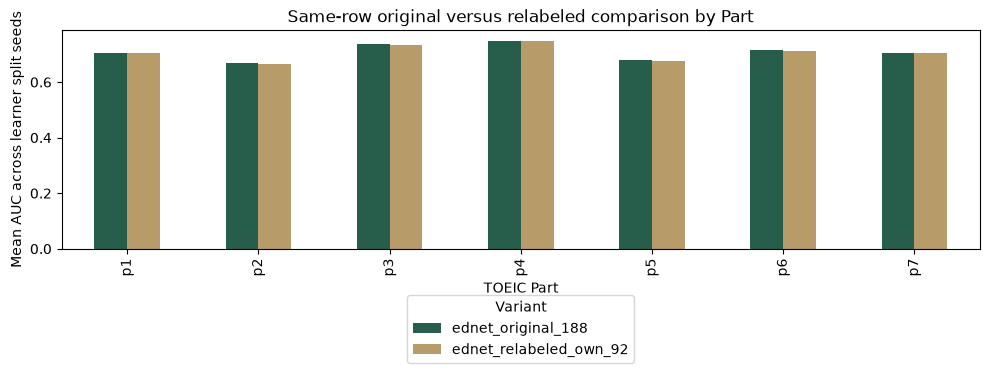

,variant,scope,auc_mean,auc_std,log_loss_mean,log_loss_std,brier_mean,brier_std,accuracy_mean,accuracy_std
1,ednet_original_188,mapped_test,0.699226,0.004439,0.589780,0.010431,0.201857,0.004343,0.689412,0.008397
9,ednet_original_188,unmapped_test,0.704188,0.008701,0.604469,0.013398,0.207960,0.006239,0.677607,0.015506
11,ednet_relabeled_own_92,mapped_test,0.696234,0.006098,0.591575,0.011485,0.202810,0.004809,0.686397,0.009371
19,ednet_relabeled_own_92,unmapped_test,0.689553,0.016174,0.612381,0.017335,0.211960,0.007668,0.661281,0.016191


In [5]:
parts=a[a.scope.isin(['p'+str(i) for i in range(1,8)])]
display(parts[['variant','scope','auc_mean','auc_std','log_loss_mean']])
wide=parts.pivot(index='scope',columns='variant',values='auc_mean')
ax=wide.plot.bar(figsize=(10,4),color=['#275d4b','#b79b68'])
ax.set(xlabel='TOEIC Part',ylabel='Mean AUC across learner split seeds',title='Same-row original versus relabeled comparison by Part')
ax.legend(title='Variant',loc='upper center',bbox_to_anchor=(.5,-.18));plt.tight_layout();plt.show()
ax.figure.savefig(OUT/'per_part_auc.png',dpi=150,bbox_inches='tight')
display(a[a.scope.isin(['mapped_test','unmapped_test'])])

## Dùng kết quả thế nào?

Kiểm tra pipeline có dùng log thật và không rò nhãn là việc khác với xác nhận taxonomy. Các nhãn OWN vẫn là proposal. Muốn tuyên bố giảm tag không mất chất lượng cần protocol, margin và tập xác nhận độc lập được chốt trước. Không sửa mapping bằng test ở lượt này rồi báo như holdout mới.

In [6]:
print((ROOT/'docs/DAS3H_COMPARISON.md').read_text(encoding='utf-8'))
assert m.converged.all()
for (_,scope),group in m.groupby(['seed','scope']): assert group.test_attempts.nunique()==1
print('All selected models converged; exact row identity checked against local real attempt cache.')
print('Private predictions/splits/interaction data are not exported into notebook.')

# DAS3H — EdNet gốc so với EdNet đổi nhãn OWN

Đã huấn luyện và test trên đáp án đúng/sai thật trong EdNet KT4. Không sinh số liệu mô phỏng.

- Cohort: 3000 người học; 413,744 lượt đã nộp; 11544 câu khác ID.
- Lấy toàn bộ lịch sử đã nộp của cohort, không giới hạn số lượt/người. Không phải toàn bộ người học KT4.
- Hai biến thể dùng chính xác cùng hàng dữ liệu và user splits. Test learner-disjoint, cập nhật lịch sử sau từng batch; không phải global calendar holdout.
- DAS3H d=0, sparse L2 logistic regression; không có latent interactions libFM. C chỉ chọn bằng validation.
- Giữ câu chưa có nhãn OWN trong cả hai biến thể; ở bản OWN những câu này vẫn có item bias nhưng không có skill features.

## AUC và log loss trên toàn bộ test

- ednet_original_188: AUC 0.699760 ± 0.004621; log loss 0.590793; Brier 0.202279.
- ednet_relabeled_own_92: AUC 0.695972 ± 0.006697; log loss 0.593015; Brier 0.203444.

± là SD giữa các split seed trên cùng cohort, không phải CI hay các fold độc lập.

## Chênh A